In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
from plot_utils_and_functions import *

In [3]:
def create_graph_from_grid(grid):
    rows, cols = grid.shape
    G = nx.Graph()

    # Get all active nodes (where grid == 1)
    nodes = np.argwhere(grid == 1)
    G.add_nodes_from(map(tuple, nodes))  # Convert to tuple for hashability

    # Define the 8 possible moves
    directions = np.array([[-1, -1], [-1, 0], [-1, 1],
                           [0, -1],          [0, 1],
                           [1, -1],  [1, 0],  [1, 1]])

    # Compute valid neighbor coordinates with periodic boundaries
    for r, c in nodes:
        for dr, dc in directions:
            nr = (r + dr) % rows  # Wrap around row boundaries
            nc = (c + dc) % cols  # Wrap around column boundaries
            if grid[nr, nc] == 1:  # Only add edges if the neighbor is also 1
                G.add_edge((r, c), (nr, nc))

    return G
    
def get_largest_connected_component(G):
    try:
        largest_cc = max(nx.connected_components(G), key=len)
        return G.subgraph(largest_cc).copy()
    except ValueError: 
        return nx.Graph() 

In [4]:
n = 300
Lx = 32
Ly = 32
eta = 0.01
decay_rate = 0.015
beta = 4.5
delta = 0.3
n_special = 1
t_transient = 200
tmax = 1200
eta_special = 0
beta_special = 1
delta_special = 1

In [5]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)

In [6]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [7]:
n_sim = 10

In [8]:
simulation = False
if simulation:
    
    all_positions = np.zeros((tmax-t_transient, n+n_special, 2))
    all_pheromones = np.zeros((tmax-t_transient, Lx, Ly))

    for sim in range(n_sim):
        for beta in beta_list:
            for delta in delta_list:
                print(f"Testing with delta = {delta}, beta = {beta}")

                env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        beta, delta, tmax, n_special, t_transient) # in this case beta, delta are beta and delta also for special ants
                
                env.reset_objects()
                env.transient()
                
                for t in range(tmax-t_transient):
                    env.update()
                    all_positions[t, :, :] = env.positions.copy()
                    all_pheromones[t, :, :] = env.pheromones.copy()

                all_positions = np.array(all_positions)
                all_pheromones = np.array(all_pheromones)
                np.savez(f"entropy/test_results_delta_{delta}_beta_{beta}_base_{sim}.npz", all_positions=all_positions, all_pheromones=all_pheromones)

In [9]:
policies = [i for i in range(n_sim)]
beta = beta_list
delta = delta_list

In [10]:
# =====================================================================
# LOOP PRINCIPALE
# =====================================================================
L = 32
lag_list = [1, 2, 5, 10, 20, 32, 50, 60]
num_lags = len(lag_list)
tau = 100

shape_3d = (len(policies), len(beta), len(delta))
shape_4d = (*shape_3d, num_lags)

collective_entropy_results = np.zeros(shape_3d)
individual_entropy_results = np.zeros(shape_3d)
individual_entropy_std_results = np.zeros(shape_3d)
mutual_info_results = np.zeros(shape_3d)
extent_results = np.zeros(shape_3d)
msd_results = np.zeros(shape_4d)
persistence_results = np.zeros(shape_4d)

for si, sim in enumerate(policies):
    for bi, b in enumerate(beta):
        for di, d in enumerate(delta):
            filename = f"entropy/test_results_delta_{d}_beta_{b}_base_{sim}.npz"
            with np.load(filename) as data:
                pos_last_tau = data["all_positions"][-tau:, :n]

            h_ind_mean, h_ind_std = compute_individual_entropy(pos_last_tau)

            collective_entropy_results[si, bi, di] = compute_collective_entropy(pos_last_tau, L)
            individual_entropy_results[si, bi, di] = h_ind_mean
            individual_entropy_std_results[si, bi, di] = h_ind_std
            mutual_info_results[si, bi, di] = compute_mutual_information(pos_last_tau)
            extent_results[si, bi, di] = compute_spatial_extent(pos_last_tau)
            msd_results[si, bi, di, :] = compute_msd(pos_last_tau, L, lag_list)
            persistence_results[si, bi, di, :] = compute_directional_persistence(pos_last_tau, L, lag_list)

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_70553/2263347148.py:6: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')
/tmp/ipykernel_70553/2263347148.py:16: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

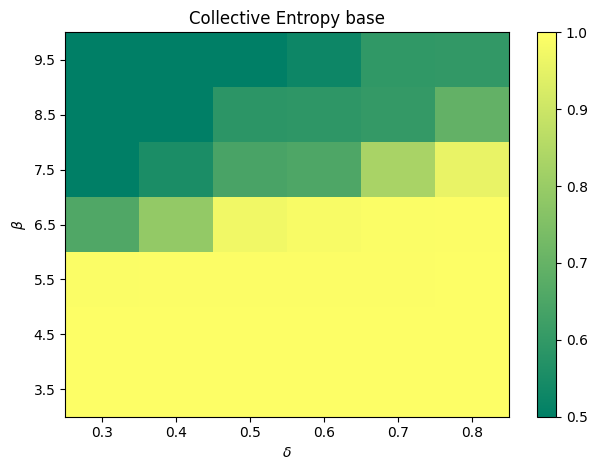

<Figure size 800x600 with 0 Axes>

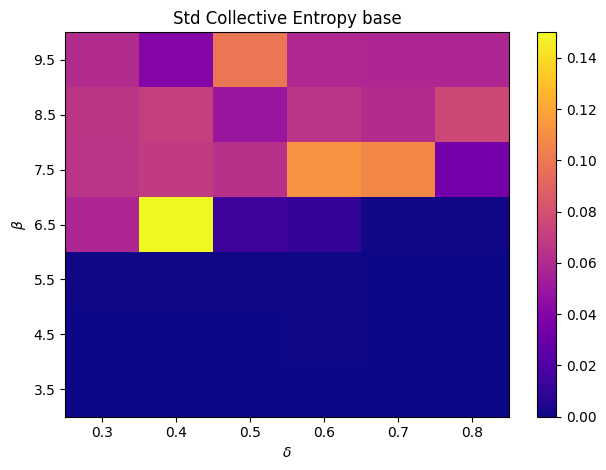

In [11]:
plt.figure(figsize=(8, 6))
entropy_results = np.mean(collective_entropy_results, axis=0)  # Media su tutte le simulazioni
'''plt.imshow(entropy_results, origin='lower', extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)],
            aspect='auto', cmap='summer', vmin=0.5, vmax=1)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')  
plt.ylabel(r'$\beta$')'''

plot_heatmap(entropy_results, delta_list, beta_list,
              title='Collective Entropy base', cmap='summer', vmin=0.5, vmax=1)
plt.figure(figsize=(8, 6))
std_entropy_results = np.std(collective_entropy_results, axis=0)  # Media su tutte le simulazioni
'''plt.imshow(std_entropy_results, origin='lower', extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)],
            aspect='auto', cmap='plasma')#, vmin=0.5, vmax=1)
plt.colorbar(label=r'${std(H)}$')
plt.xlabel(r'$\delta$')  
plt.ylabel(r'$\beta$')'''

plot_heatmap(std_entropy_results, delta_list, beta_list,
              title='Std Collective Entropy base', cmap='plasma', vmin=0.0, vmax=0.15)

<>:16: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244379/2067527203.py:16: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

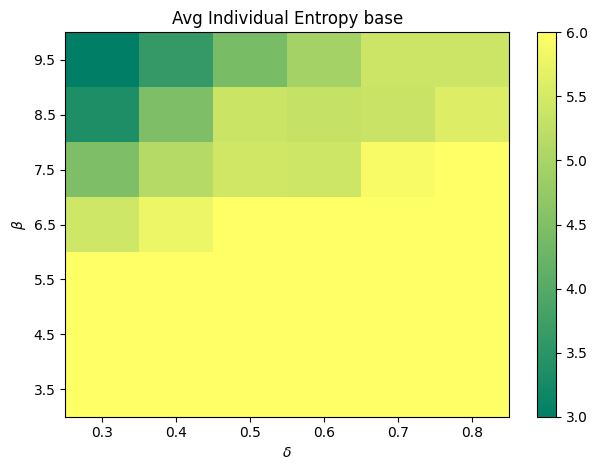

In [12]:
plt.figure(figsize=(8, 6))
avg_entropy = individual_entropy_results.mean(axis=0)  # Media su tutte le simulazioni  
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.imshow(
    avg_entropy,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='summer',
    vmin=3,
    vmax=6
)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')'''

plot_heatmap(avg_entropy, delta_list, beta_list,
              title='Avg Individual Entropy base', cmap='summer', vmin=3, vmax=6)

<>:14: SyntaxWarning: invalid escape sequence '\d'
<>:14: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244379/870240680.py:14: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

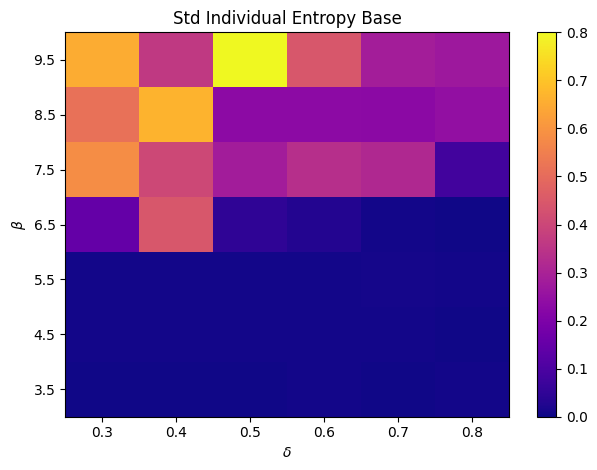

In [16]:
plt.figure(figsize=(8, 6))
std_entropy = individual_entropy_results.std(axis=0)  # Media su tutte le simulazioni  
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.imshow(
    std_entropy,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='plasma'
)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')'''

plot_heatmap(std_entropy, delta_list, beta_list,
              title='Std Individual Entropy Base', cmap='plasma', vmin=0.0, vmax=0.8)

<>:21: SyntaxWarning: invalid escape sequence '\d'
<>:21: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244379/1049793028.py:21: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


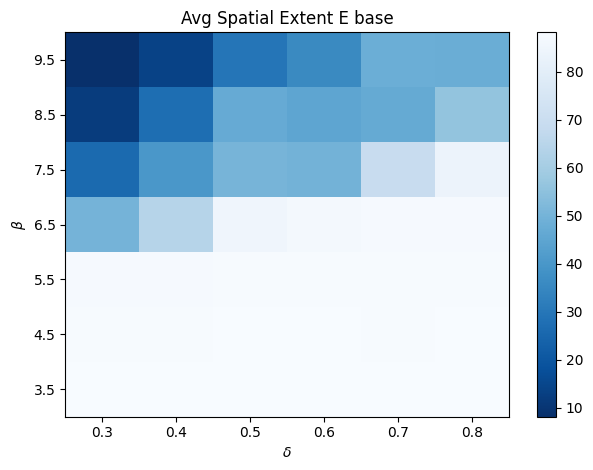

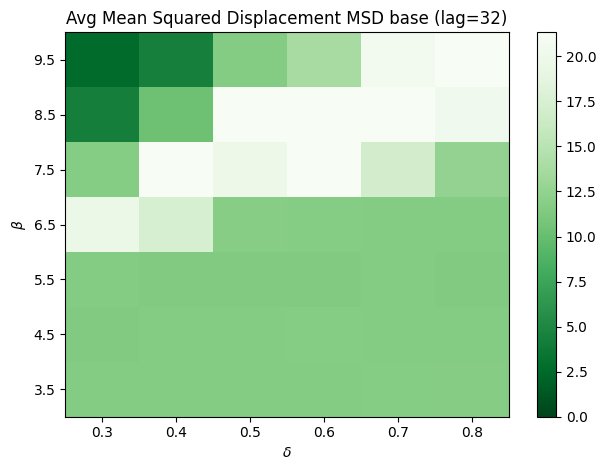

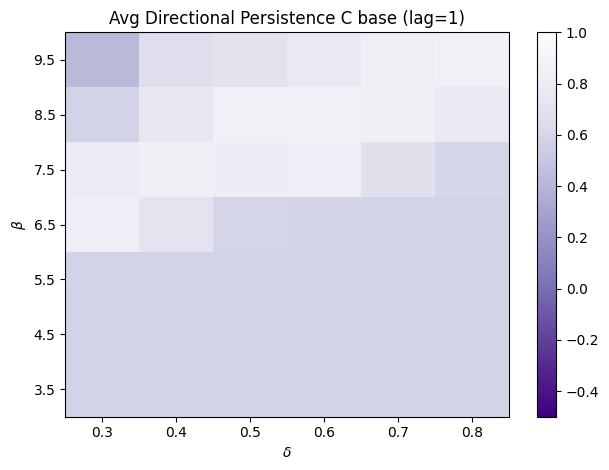

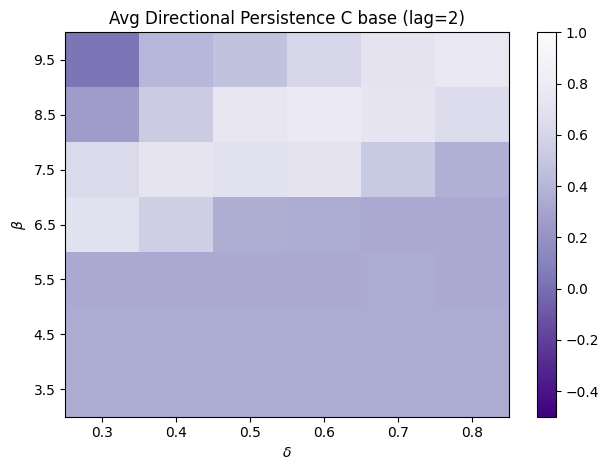

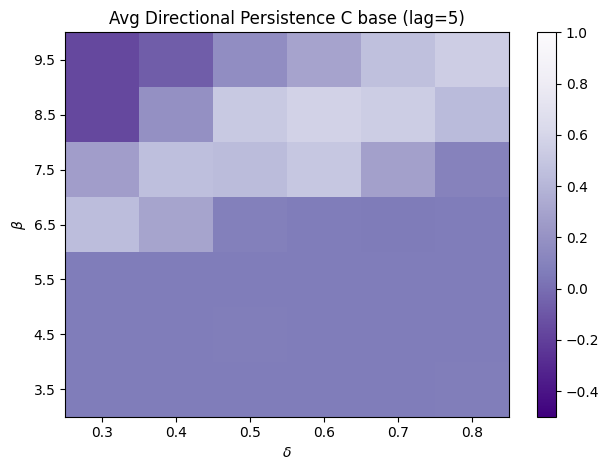

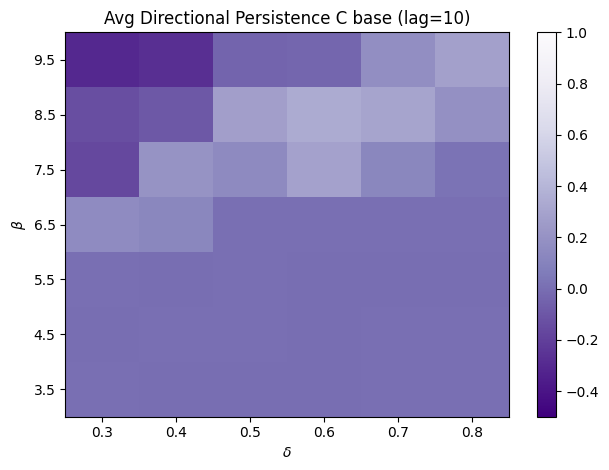

In [14]:
# 1. Media dell'Informazione Mutua lungo le simulazioni (axis=0)
avg_extent_results = np.mean(extent_results, axis=0)
avg_msd_results = np.mean(msd_results, axis=0)
avg_persistence_results = np.mean(persistence_results, axis=0)
chosen_lag = 32  # Lag scelto per visualizzare MSD(l) e C(l)
index_of_chosen_lag = lag_list.index(chosen_lag)  # Ottieni l'indice del lag scelto
lags_for_directional_persistence = [1,2,5,10]
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_extent_results,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Blues_r'
)
plt.colorbar(label=r'$E$')

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Spatial Extent $E$ base')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_msd_results[:,:,index_of_chosen_lag],  # Visualizza MSD al lag scelto
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Greens_r',
    vmin=0, vmax=chosen_lag*2/3
)
plt.colorbar(label=r'$MSD(l)$')  # Aggiunta della barra del colore per MSD

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Mean Squared Displacement $MSD(l)$ base')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_persistence_results[:,:,index_of_chosen_lag],  # Visualizza C(l) al lag scelto
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Purples_r'
)
plt.colorbar(label=r'$C(l)$')  # Aggiunta della barra del colore per C(l)

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Directional Persistence $C(l)$ base')
plt.tight_layout()
plt.show()'''

plot_heatmap(avg_extent_results, delta_list, beta_list,
              title='Avg Spatial Extent E base', cmap='Blues_r')
plot_heatmap(avg_msd_results[:,:,index_of_chosen_lag], delta_list, beta_list,
              title=f'Avg Mean Squared Displacement MSD base (lag={chosen_lag})', cmap='Greens_r', vmin=0, vmax=chosen_lag*2/3)

for lag_for_directional_persistence in lags_for_directional_persistence:
    index_of_lag_for_directional_persistence = lag_list.index(lag_for_directional_persistence)  # Ottieni l'indice del lag scelto per la persistenza direz
    plot_heatmap(avg_persistence_results[:,:,index_of_lag_for_directional_persistence], delta_list, beta_list,
              title=f'Avg Directional Persistence C base (lag={lag_for_directional_persistence})', cmap='Purples_r',
                vmin=-0.5, vmax=1)

<>:20: SyntaxWarning: invalid escape sequence '\d'
<>:20: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244379/1114956105.py:20: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


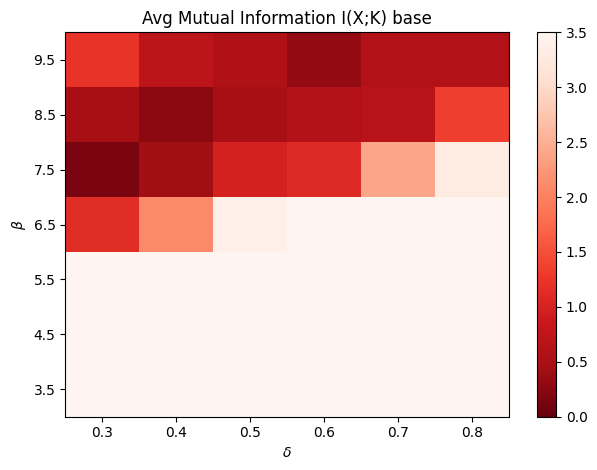

In [15]:
# 1. Media dell'Informazione Mutua lungo le simulazioni (axis=0)
avg_mutual_info = np.mean(mutual_info_results, axis=0)

'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

# 2. Creazione della figura
plt.figure(figsize=(8, 6))
plt.imshow(
    avg_mutual_info,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Reds_r',  # 'viridis' o 'plasma' mettono in risalto i valori di informazione mutua; puoi usare 'summer' se preferisci la stessa palette
    vmin=0,        # scommenta e imposta se vuoi fissare la scala minima
    vmax=3.5        # scommenta e imposta se vuoi fissare la scala massima
)

plt.colorbar(label=r'$I(X; K)$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Mutual Information $I(X; K)$ base')
plt.tight_layout()
plt.show()'''

plot_heatmap(avg_mutual_info, delta_list, beta_list,
              title='Avg Mutual Information I(X;K) base', cmap='Reds_r', vmin=0, vmax=3.5)